In [1]:
import onnxruntime as ort
import numpy as np
import json
import uproot
import pandas as pd
import matplotlib.pyplot as plt
import mplhep
from sklearn import metrics
from scipy.integrate import simpson
from scipy.integrate import trapezoid
from scipy.stats import distributions
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import KFold
from scipy.stats import chisquare
import xgboost 
import pickle
import json
from scipy.stats import chisquare
import warnings
from collections import defaultdict #for feature imp avg
import seaborn as sns
from pprint import pprint
from matplotlib.ticker import FuncFormatter  #for y-axis scaling for histograms
import matplotlib.ticker as mtick

In [2]:
# Initialize the counter
if 'execution_count' not in globals():
    execution_count = 0


In [62]:
mplhep.style.use('ATLAS')
nbins = 10

In [4]:
# KS Test
def ks_weighted(data1, data2, wei1, wei2, alternative='two-sided'):
    data1 = np.array(data1)
    data2 = np.array(data2)
    wei1 = np.array(wei1)
    wei2 = np.array(wei2)
    
    ix1 = np.argsort(data1)
    ix2 = np.argsort(data2)
    data1 = data1[ix1]
    data2 = data2[ix2]
    wei1 = wei1[ix1]
    wei2 = wei2[ix2]
    data = np.concatenate([data1, data2])
    cwei1 = np.hstack([0, np.cumsum(wei1)/sum(wei1)])
    cwei2 = np.hstack([0, np.cumsum(wei2)/sum(wei2)])
    cdf1we = cwei1[np.searchsorted(data1, data, side='right')]
    cdf2we = cwei2[np.searchsorted(data2, data, side='right')]
    d = np.max(np.abs(cdf1we - cdf2we))
    # calculate p-value
    n1 = data1.shape[0]
    n2 = data2.shape[0]
    m, n = sorted([float(n1), float(n2)], reverse=True)
    en = m * n / (m + n)
    if alternative == 'two-sided':
        prob = distributions.kstwo.sf(d, np.round(en))
    else:
        z = np.sqrt(en) * d
        # Use Hodges' suggested approximation Eqn 5.3
        # Requires m to be the larger of (n1, n2)
        expt = -2 * z**2 - 2 * z * (m + 2*n)/np.sqrt(m*n*(m+n))/3.0
        prob = np.exp(expt)
    return d, prob

In [5]:


feature_cols = ['jet_pt[:,0]',
                'jet_pt[:,1]', 
                #'jet_pt[:,2]', 
                #'jet_pt[:,3]',
                #'jet_e[:,0]',
                #'jet_e[:,1]', 
                #'jet_e[:,2]', 
                #'jet_e[:,3]', 
                'met_met',
                # 'met_phi',
                'ph_eta[:,0]', 
                'ph_eta[:,1]',
                'ph_pt[:,0]', 
                'ph_pt[:,1]',
                #'ph_e[:,0]', 
                #'ph_e[:,1]', 
                #'ph_phi[:,0]', 
                #'ph_phi[:,1]',
                'ph_mlph_closest[:,0]', 
                'ph_mlph_closest[:,1]',
                'diph_M', 
                #'event_njets',
                #'event_HT', 
                #'event_ST', 
                'event_nbjets70', 
                'dr_lep_ph0', 
                'dr_lep_ph1',
                'ph_conversion_type[:,1]', 
                'ph_conversion_type[:,0]',
                'ph_mphb70_closest[:,0]',
                'ph_mphb70_closest[:,1]',
                #'ph_drphb77_leading_pt[:,0]', 
                #'ph_drphb77_leading_pt[:,1]',
                'm_AllObjects',
                #'m_ph_bjet', 
                 #'dr_lep_bjetscore', 
                #'jet_DL1r_bjetscore',
                'jet_tagWeightBin_DL1r_Continuous_Max',
                'dr_ph'
                  ]
                  


# Update the counter
global execution_count
execution_count += 1
print(f"This cell has been run {execution_count} times.")


This cell has been run 1 times.


In [6]:
len(feature_cols)

20

In [7]:
cols = feature_cols+['eventNumber','weight']
aliases = {'weight':'event_norm * weight_mc * weight_pileup * weight_leptonSF * weight_photonSF * weight_jvt * weight_bTagSF_DL1r_Continuous * event_lumi'}

In [17]:
df_sig = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)',library="pd",aliases=aliases)


In [58]:
n_estimators = 50

In [64]:
# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg['weight'][df_bkg['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg['weight'][df_bkg['eventNumber']%nfolds == fold]
    
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    print("Signal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test(events,weights): ", len(X_bkg_train), len(w_bkg_train), len(X_bkg_test), len(w_bkg_test))
    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_WP70_Model{execution_count}_PCBTBinVariable_Fold{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

Signal train test(events,weights):  243054 243054 80846 80846
Background train test(events,weights):  2052 2052 674 674
Train scores 0: [0.7071737796569605]
Test scores 0:  [0.6700743869360747]
50
Signal train test(events,weights):  242986 242986 80914 80914
Background train test(events,weights):  2084 2084 642 642
Train scores 1: [0.7071737796569605, 0.6965678777695888]
Test scores 1:  [0.6700743869360747, 0.6779929869773276]
50
Signal train test(events,weights):  242824 242824 81076 81076
Background train test(events,weights):  2038 2038 688 688
Train scores 2: [0.7071737796569605, 0.6965678777695888, 0.7037760955811664]
Test scores 2:  [0.6700743869360747, 0.6779929869773276, 0.6497973090364915]
50
Signal train test(events,weights):  242836 242836 81064 81064
Background train test(events,weights):  2004 2004 722 722
Train scores 3: [0.7071737796569605, 0.6965678777695888, 0.7037760955811664, 0.7022153315838324]
Test scores 3:  [0.6700743869360747, 0.6779929869773276, 0.6497973090364

In [65]:
mplhep.style.use('ATLAS')

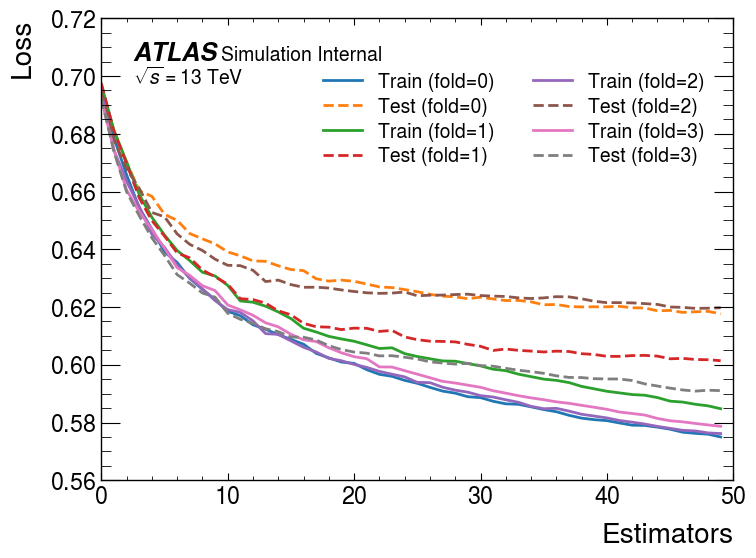

In [66]:
    
    
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend(title=' ',ncols=2)
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
#plt.savefig(f'loss_curve.pdf')

plt.show()

In [67]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.73611516, 0.62161034, 0.8394338 , ..., 0.76428676, 0.7653329 ,
       0.74415785], dtype=float32), array([0.52872986, 0.57521677, 0.8021148 , ..., 0.7317528 , 0.68946505,
       0.7460638 ], dtype=float32), array([0.588662  , 0.61456275, 0.8273741 , ..., 0.80720705, 0.68581426,
       0.77445376], dtype=float32), array([0.63978076, 0.56926954, 0.8036585 , ..., 0.7503628 , 0.7022941 ,
       0.7309314 ], dtype=float32)]
Bkg:  [array([0.4311958 , 0.70793146, 0.46852142, ..., 0.4020289 , 0.5193611 ,
       0.580278  ], dtype=float32), array([0.50287557, 0.70136243, 0.5208196 , ..., 0.3918402 , 0.5878498 ,
       0.5993515 ], dtype=float32), array([0.58389693, 0.6390739 , 0.4599175 , ..., 0.4467536 , 0.59734845,
       0.6064749 ], dtype=float32), array([0.4768062 , 0.78706974, 0.37603635, ..., 0.334067  , 0.56399935,
       0.59006464], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  2726


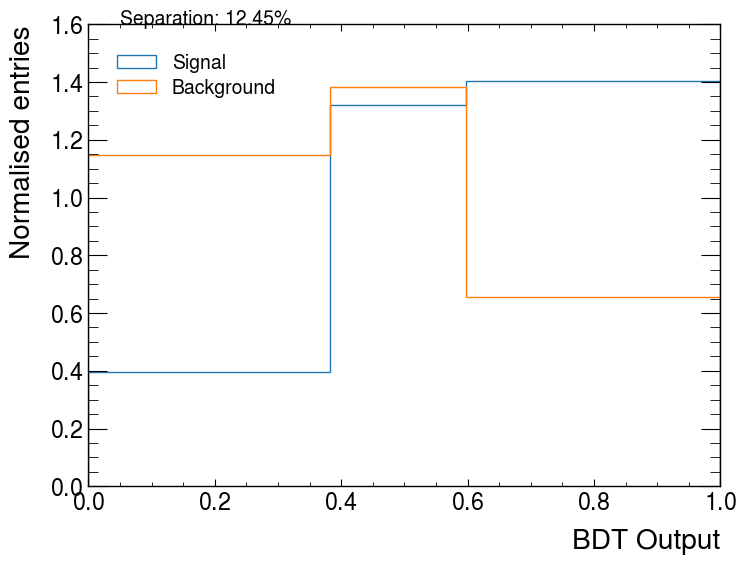

In [68]:

# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.pdf')
plt.legend()


sig histogram values:  [0.00285779 0.2033632  0.5898512  0.89482068 1.16924337 1.53027211
 1.88342451 2.12665948 1.54758239 0.05192592]
bkg histogram values:  [0.04672572 0.96314398 1.8612865  1.80816638 1.2712364  1.43597561
 1.16304863 1.01431416 0.43211262 0.00399009]


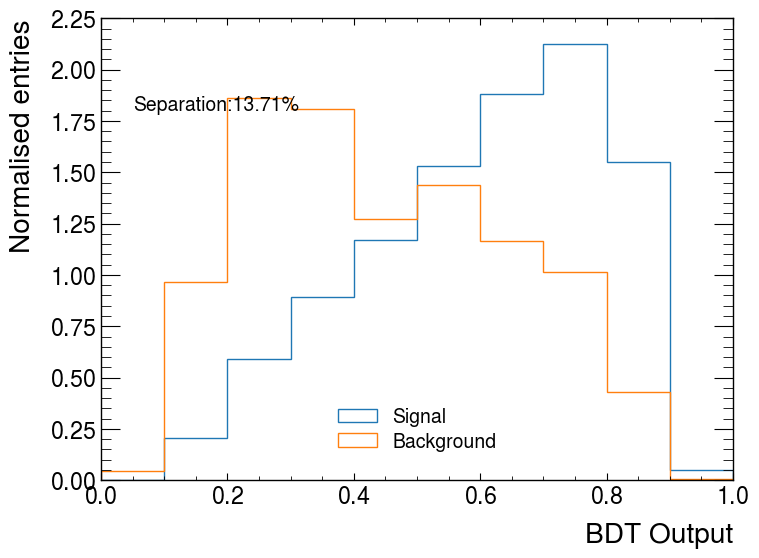

In [69]:
# Considering Negative Weights

bc_sig,_,_ = plt.hist(results_sig, weights=(df_sig['weight']),  range=(0,1), bins=nbins, histtype='step', density=True, label='Signal')
bc_bkg,_,_ = plt.hist(results_bkg, weights=(df_bkg['weight']), range=(0,1), bins=nbins, histtype='step', density=True, label='Background')
print('sig histogram values: ',bc_sig )
print('bkg histogram values: ',bc_bkg )

separation = 0.5 * np.sum(np.nan_to_num(((bc_sig/nbins - bc_bkg/nbins) ** 2) / (bc_sig/nbins + bc_bkg/nbins)))

plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
#mplhep.atlas.label('WIP', data=False, ax=ax)
plt.text(x=0.05, y=1.8,s=F'Separation:{separation*100:.2f}%')
#plt.savefig(f'separation.pdf')
plt.legend()

(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

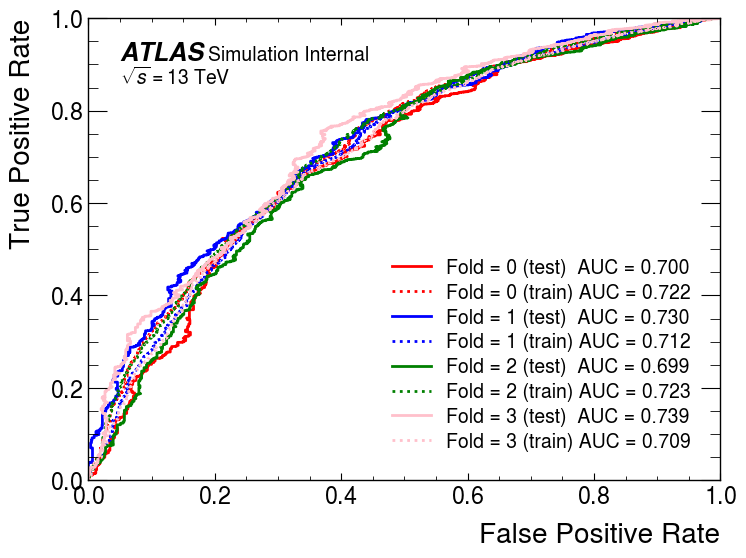

In [70]:
folds = 4
#fig, axes = plt.subplots(nrows=2,ncols=2, figsize=(12,10))
#axes = axes.reshape(-1)
colors = ['red','blue','green','pink'] 
for fold in range(folds):
    results_sig_fold_test = results_sig[df_sig['eventNumber']%folds == fold]
    results_bkg_fold_test = results_bkg[df_bkg['eventNumber']%folds == fold]
    weights_sig_fold_test = df_sig['weight'][df_sig['eventNumber']%folds == fold]
    weights_bkg_fold_test = df_bkg['weight'][df_bkg['eventNumber']%folds == fold]
    y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
    scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
    weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])
    fpr, tpr, thresholds = metrics.roc_curve(y, scores, sample_weight=weights,pos_label=1)
    #AUC = metrics.roc_auc_score(y, scores)
    AUC = trapezoid(y=tpr,x=fpr)
    plt.plot(fpr,tpr,label=F'Fold = {fold} (test)  AUC = {AUC:.3f}', color=colors[fold])
    
    results_sig_fold_train = results_sig[df_sig['eventNumber']%folds != fold]
    results_bkg_fold_train = results_bkg[df_bkg['eventNumber']%folds != fold]
    weights_sig_fold_train = df_sig['weight'][df_sig['eventNumber']%folds != fold]
    weights_bkg_fold_train = df_bkg['weight'][df_bkg['eventNumber']%folds != fold]
    y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
    scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
    weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])
    fpr, tpr, thresholds = metrics.roc_curve(y, scores, sample_weight=weights, pos_label=1)
    AUC = trapezoid(y=tpr,x=fpr)
    plt.plot(fpr,tpr,label=F'Fold = {fold} (train) AUC = {AUC:.3f}', color=colors[fold], linestyle='dotted')

plt.legend()
plt.xlim(0,1)
plt.ylim(0,1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)   # true to remove Simulation
#plt.savefig(f'auc.pdf')


Features with Average Importance (Descending):
Feature Name: ph_conversion_type[:,0], Average Importance: 0.21562805771827698
Feature Name: ph_conversion_type[:,1], Average Importance: 0.2058437019586563
Feature Name: dr_lep_ph1, Average Importance: 0.1023106500506401
Feature Name: ph_mlph_closest[:,1], Average Importance: 0.09746416844427586
Feature Name: dr_lep_ph0, Average Importance: 0.05239487532526255
Feature Name: ph_eta[:,1], Average Importance: 0.03217347664758563
Feature Name: ph_mphb70_closest[:,0], Average Importance: 0.029356866609305143
Feature Name: ph_eta[:,0], Average Importance: 0.02790462225675583
Feature Name: ph_mphb70_closest[:,1], Average Importance: 0.027223264332860708
Feature Name: ph_mlph_closest[:,0], Average Importance: 0.026433891151100397
Feature Name: jet_pt[:,1], Average Importance: 0.024721854366362095
Feature Name: event_nbjets70, Average Importance: 0.024333117064088583
Feature Name: dr_ph, Average Importance: 0.024046354461461306
Feature Name: met_m

<Figure size 1200x800 with 0 Axes>

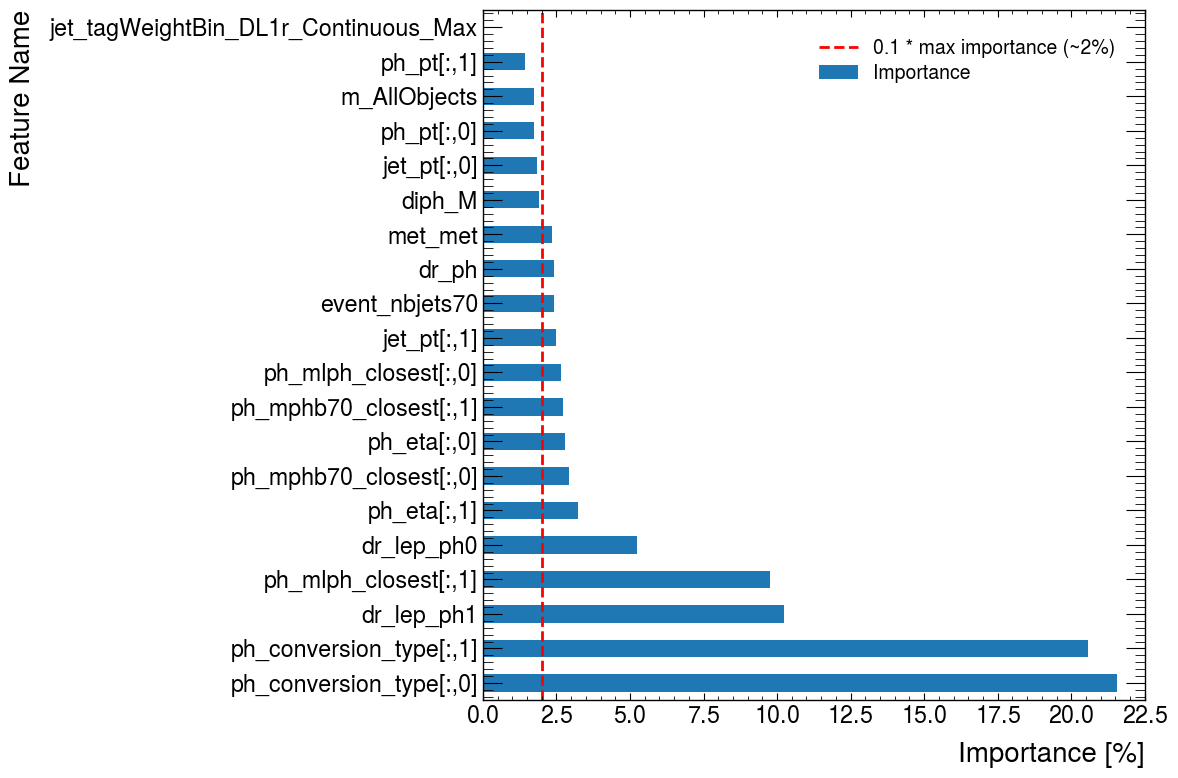

In [57]:
import matplotlib.pyplot as plt
import pandas as pd

def average_feature_importances(models, feature_cols):
  """
  This function calculates the average importance for each feature across all folds/models.

  Args:
      models: A list of XGBoost classifier models.
      feature_cols: A list of feature column names.

  Returns:
      A dictionary containing feature name and its average importance across all folds.
  """
  # Initialize a dictionary to store average importance
  average_importances = {feature: 0.0 for feature in feature_cols}

  # Iterate through each model and accumulate importance for each feature
  for model in models:
    importance_scores = model.feature_importances_  # Access feature importance attribute
    for feature, importance in zip(feature_cols, importance_scores):
      average_importances[feature] += importance

  # Calculate average importance by dividing by the total number of models
  num_models = len(models)
  for feature in average_importances:
    average_importances[feature] /= num_models

  # Sort features by importance in descending order
  sorted_importances = sorted(average_importances.items(), key=lambda x: x[1], reverse=True)
  return sorted_importances

# Assuming models and feature_cols are available (replace with your actual data)
average_importances = average_feature_importances(models, feature_cols)

# Print features with average importance (sorted by descending importance)
print("Features with Average Importance (Descending):")
for feature, importance in average_importances:
  print(f"Feature Name: {feature}, Average Importance: {importance}")

# Create DataFrame from sorted importance and plot as horizontal bar chart
importance_df = pd.DataFrame(average_importances, columns=['Feature', 'Importance'])
importance_df['Importance'] *= 100  # Scale importance to percentage

plt.figure(figsize=(12, 8))
importance_df.set_index('Feature').plot.barh(legend=False, figsize=(12, 8))
plt.xlabel('Importance [%]', fontsize=20)
plt.ylabel('Feature Name', fontsize=20)

# Optional: Add a threshold line (adjust threshold value as needed)
plt.axvline(2.0, color='red', linestyle='--', label='0.1 * max importance (~2%)')
plt.legend()
#plt.savefig(f'Feature_importance_average_Model6.pdf')

plt.tight_layout()
plt.show()


In [105]:
for i, model in enumerate(models):
    # Assuming model[0] has the feature importance scores
    feature_importances = models[i].feature_importances_

    # Create a list of tuples with feature name and importance
    feature_imp_list = zip(feature_cols, feature_importances)
    print(feature_imp_list) 
    # Sort the list based on importance in ascending order (key=lambda x: x[1])
    sorted_features = sorted(feature_imp_list, key=lambda x: x[1])
    print(f'for model: {i}')
    # Print the sorted features
    for feature, importance in sorted_features:
        print(f"Feature Name: {feature}, Importance: {importance}")
        
    print(F"No. of features: {len(sorted_features)}")

for model: 0
Feature Name: diph_M, Importance: 0.020778506994247437
Feature Name: m_AllObjects, Importance: 0.02209719642996788
Feature Name: ph_pt[:,0], Importance: 0.022784927859902382
Feature Name: ph_mlph_closest[:,0], Importance: 0.023761354386806488
Feature Name: jet_pt[:,0], Importance: 0.025089861825108528
Feature Name: ph_pt[:,1], Importance: 0.02620004117488861
Feature Name: met_met, Importance: 0.026568641886115074
Feature Name: jet_DL1r_bjetscore, Importance: 0.026715319603681564
Feature Name: ph_mphb70_closest[:,1], Importance: 0.027384640648961067
Feature Name: ph_eta[:,0], Importance: 0.030024560168385506
Feature Name: ph_mphb70_closest[:,0], Importance: 0.030101966112852097
Feature Name: jet_pt[:,1], Importance: 0.03012244589626789
Feature Name: dr_ph, Importance: 0.03096022829413414
Feature Name: ph_eta[:,1], Importance: 0.04277438297867775
Feature Name: dr_lep_ph0, Importance: 0.04580411687493324
Feature Name: ph_mlph_closest[:,1], Importance: 0.051252223551273346
Fea

In [30]:
# Define the custom formatter function
def custom_formatter(x, pos):
    return f'{x * 0.1:.1f}'

-----------------------------------------------
0.011625640847816523 2.0713744535055523
0.008687638229187635 2.1212252834116487
11 10 10
Signal train histogram: [0.01162564 0.22261778 0.53909694 0.81787607 1.09688311 1.41594871
 1.76171339 2.07137445 1.8214068  0.2414579 ]
Signal test histogram: [0.00868764 0.21023017 0.55187992 0.79738675 1.04020069 1.34317816
 1.6931844  2.12122528 1.94087803 0.29314969]
Background train histogram: [0.15948461 0.89256286 1.69559787 1.45427746 1.53291835 1.28831389
 1.25246204 1.01103208 0.68193393 0.0314169 ]
Background test histogram: [0.03487952 1.30900756 1.82108746 1.76628232 1.05376869 1.30297736
 1.18221133 1.1437732  0.24553563 0.14047811]
-----------------------------------------------

Signal train errors: [0.00221048 0.00971812 0.01510401 0.01857536 0.02150425 0.02441326
 0.02724717 0.02954059 0.02772125 0.01011687]
Signal test errors: [0.00109136 0.00546753 0.00886012 0.01060127 0.01210426 0.01375792
 0.01542829 0.01726958 0.01653051 0.006

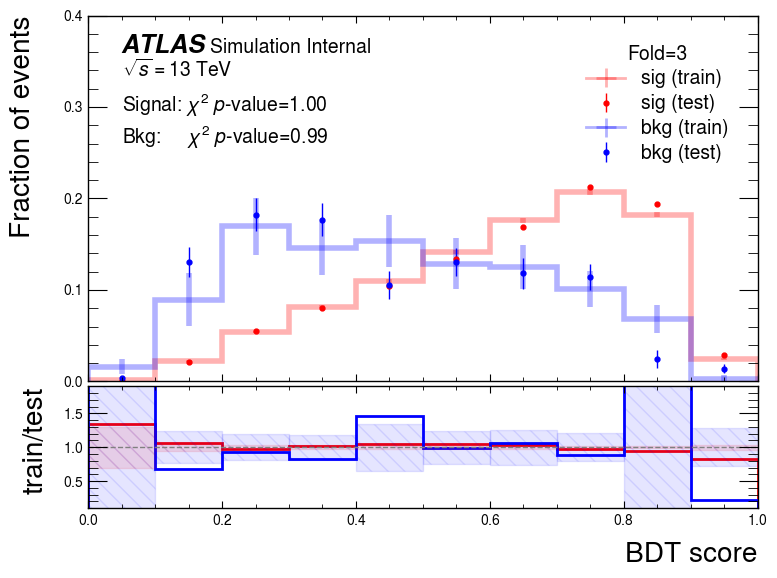

In [31]:
# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 3
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)


# Example dummy data and plots:
results_sig_fold_test = results_sig[df_sig['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg[df_bkg['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig['weight'][df_sig['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg['weight'][df_bkg['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig[df_sig['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg[df_bkg['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig['weight'][df_sig['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg['weight'][df_bkg['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=10, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=10, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=10, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=10, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)




print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




#y1 = bc_sig_train
#y1err = np.sqrt(sumW2) # calculated from sig train
#y2 = bc_sig_test
#y2err = np.sqrt(sumW2) # calculated from sig test






# Errors on histograms:
#bc_sig_train_e = np.sqrt(bc_sig_train/total_sig_train)*10  #np.sqrt(bc_sig_train)
#bc_sig_test_e = np.sqrt(bc_sig_test/total_sig_test)*10  #np.sqrt(bc_sig_test)
#bc_bkg_train_e = np.sqrt(bc_bkg_train/total_bkg_train)*10  #np.sqrt(bc_bkg_train)
#bc_bkg_test_e = np.sqrt(bc_bkg_test/total_bkg_test)*10  #np.sqrt(bc_bkg_test)





print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Ratio plot
#ratio_sig = bc_sig_train/bc_sig_test # np.divide(bc_sig_train, bc_sig_test, out=np.zeros_like(bc_sig_train), where=bc_sig_test != 0)
#ratio_bkg = bc_bkg_train/bc_bkg_test #  np.divide(bc_bkg_train, bc_bkg_test, out=np.zeros_like(bc_bkg_train), where=bc_bkg_test != 0)
#print(bb)
#print(ratio_sig)
#print(ratio_bkg)
#print(len(bb), len(ratio_sig), len(ratio_bkg))

# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)




bb_centers = (bb[:-1] + bb[1:]) / 2
#axes[1].plot(bb_centers, ratio_sig, 'o', label='Sig', color='red', linestyle='None', markersize=5)
#axes[1].plot(bb_centers, ratio_bkg, 'o', label='Bkg', color='blue', linestyle='None', markersize=5)
#axes[1].axhline(1,0,1,linestyle='--',color='grey')

mplhep.histplot(ratio_sig, bb, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, bb, histtype='step', ax=axes[1], color='blue', linewidth=2)


# Plot with clipped errors
#axes[1].fill_between(bb_centers, y1=(ratio_sig + clipped_errors_sig), y2=(ratio_sig - clipped_errors_sig), alpha=0.2, color='red')
#axes[1].fill_between(bb_centers, y1=(ratio_bkg + clipped_errors_bkg), y2=(ratio_bkg - clipped_errors_bkg), alpha=0.2, color='blue')

#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), alpha=0.2, color='red', hatch='\\\\', zorder=1) 
#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), alpha=0.2, color='blue', hatch='/', zorder=1) 


# Plot the ratio uncertainty bands with hatch styles
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='none', edgecolor='red', hatch='\\\\', zorder=1, linewidth=0.0)
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), facecolor='none', edgecolor='#CCCCFF', hatch='///', zorder=1, linewidth=0.0)


#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='red', alpha=0.2, edgecolor='red', hatch='\\\\', zorder=1)

bin_width = bb[1] - bb[0] 
# Plot the uncertainty band in histogram style using bar
for center, err in zip(bb_centers, clipped_errors_sig):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')
for center, err in zip(bb_centers, clipped_errors_bkg):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
#fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model6.png')

In [20]:
bkg_corr_matrix = df_bkg[feature_cols].corr()
sig_corr_matrix = df_sig[feature_cols].corr()

#bkg_corr_matrix.to_csv('bkg_correlation_matrix.csv', index=True)  # Save to CSV


In [145]:
plt.figure(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = sig_corr_matrix.values  # Assuming sig_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides

plt.savefig('sig_correlation_heatmap_seaborn_large_white_Model6.png', dpi=500, bbox_inches='tight')


NameError: name 'sig_corr_matrix' is not defined

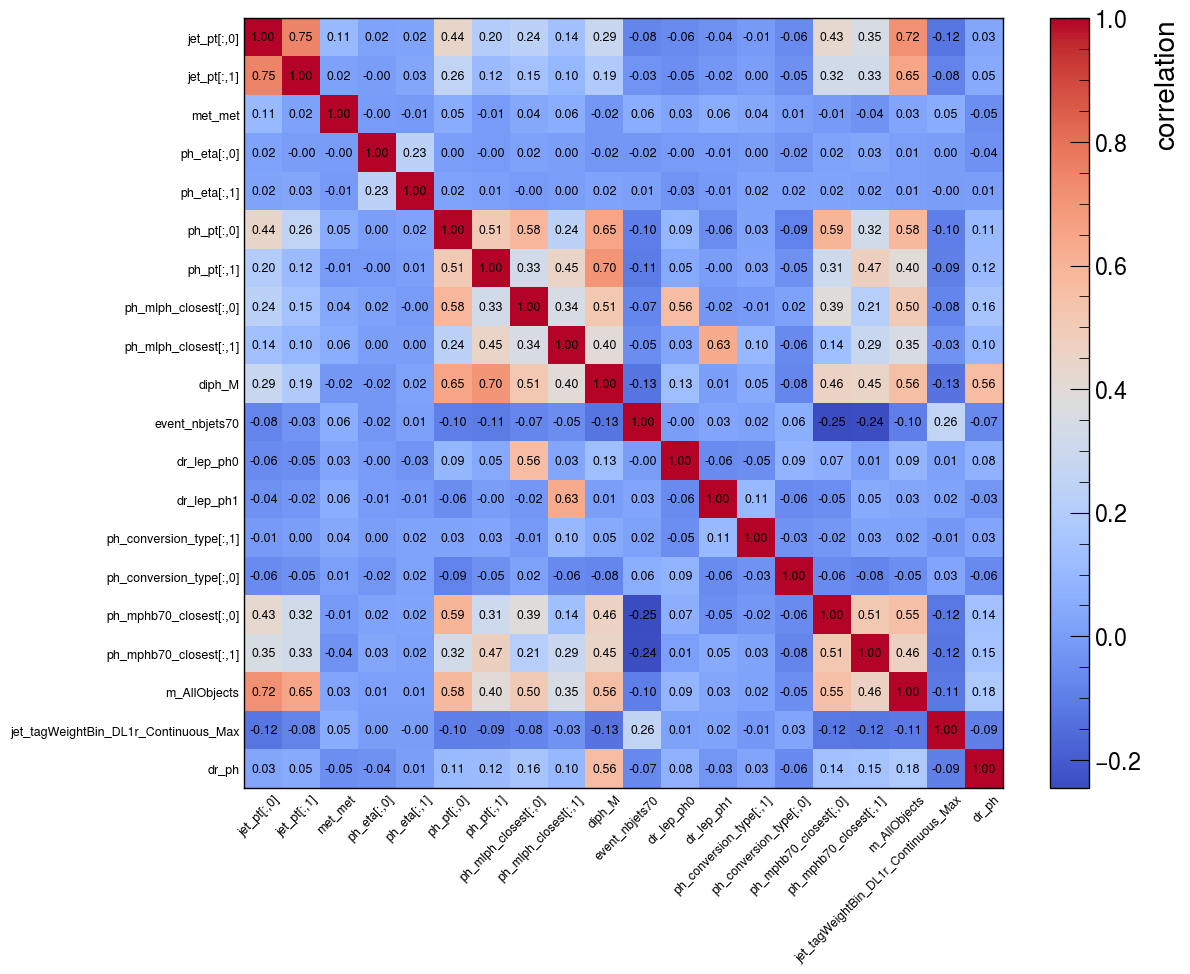

In [24]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = bkg_corr_matrix.values  # Assuming bkg_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides


plt.savefig('bkg_correlation_heatmap_seaborn_large_white_Model6.png', dpi=500, bbox_inches='tight')



In [72]:
print(len(df_sig)), print(len(df_bkg))

323900
2726


(None, None)

# Training without weights

In [79]:
df_sig = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [97]:
n_estimators = 11

# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg['weight'][df_bkg['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg['weight'][df_bkg['eventNumber']%nfolds == fold]
    
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    print("Signal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test(events,weights): ", len(X_bkg_train), len(w_bkg_train), len(X_bkg_test), len(w_bkg_test))
    
    
    scale_pos_weight = len(df_bkg) /len(df_sig)
    print("Scaled weight:", scale_pos_weight )
    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators, scale_pos_weight=scale_pos_weight)
    model.fit(X_train, y_train) #using no weights
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_WP70_Model{execution_count}_PCBTBinVariable_Fold{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

Signal train test(events,weights):  243054 243054 80846 80846
Background train test(events,weights):  2977 2977 982 982
Scaled weight: 0.012222908305032417
Train scores 0: [0.7192327818788703]
Test scores 0:  [0.6185070570429348]
11
Signal train test(events,weights):  242986 242986 80914 80914
Background train test(events,weights):  3009 3009 950 950
Scaled weight: 0.012222908305032417
Train scores 1: [0.7192327818788703, 0.7062145102194295]
Test scores 1:  [0.6185070570429348, 0.6618578668538145]
11
Signal train test(events,weights):  242824 242824 81076 81076
Background train test(events,weights):  2965 2965 994 994
Scaled weight: 0.012222908305032417
Train scores 2: [0.7192327818788703, 0.7062145102194295, 0.7119060337786373]
Test scores 2:  [0.6185070570429348, 0.6618578668538145, 0.6300354229113636]
11
Signal train test(events,weights):  242836 242836 81064 81064
Background train test(events,weights):  2926 2926 1033 1033
Scaled weight: 0.012222908305032417
Train scores 3: [0.7192

In [98]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.5973832 , 0.6594175 , 0.7608347 , ..., 0.6889858 , 0.7572589 ,
       0.50668764], dtype=float32), array([0.59660804, 0.7114556 , 0.7035982 , ..., 0.703628  , 0.82655424,
       0.5932876 ], dtype=float32), array([0.5727652 , 0.67785627, 0.7444161 , ..., 0.7122035 , 0.7247686 ,
       0.63201535], dtype=float32), array([0.56843305, 0.5997635 , 0.63211745, ..., 0.6668736 , 0.73905194,
       0.6687818 ], dtype=float32)]
Bkg:  [array([0.29605174, 0.4833298 , 0.6839456 , ..., 0.65346646, 0.31930736,
       0.5342801 ], dtype=float32), array([0.2476918 , 0.5712905 , 0.6853582 , ..., 0.25601193, 0.23665956,
       0.38075542], dtype=float32), array([0.46637568, 0.47427338, 0.6844919 , ..., 0.43521774, 0.25346854,
       0.32093012], dtype=float32), array([0.3693731 , 0.59884316, 0.71809036, ..., 0.26963624, 0.351966  ,
       0.3728379 ], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3959


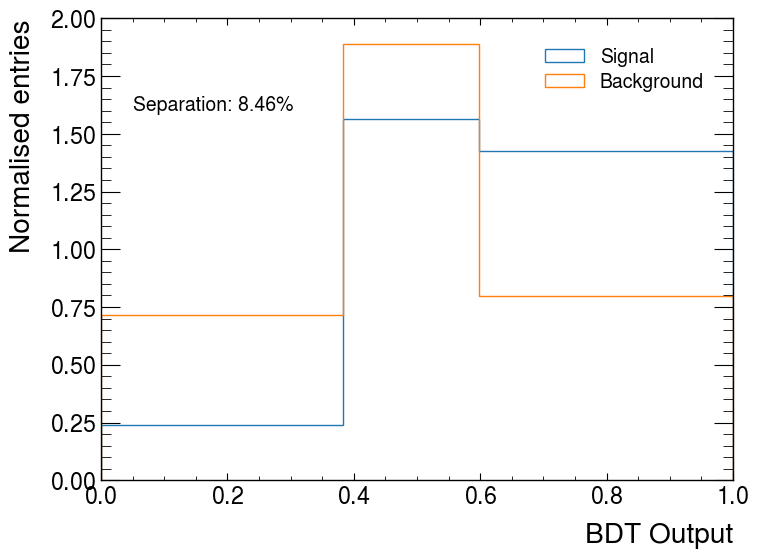

In [99]:

# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.pdf')
plt.legend()


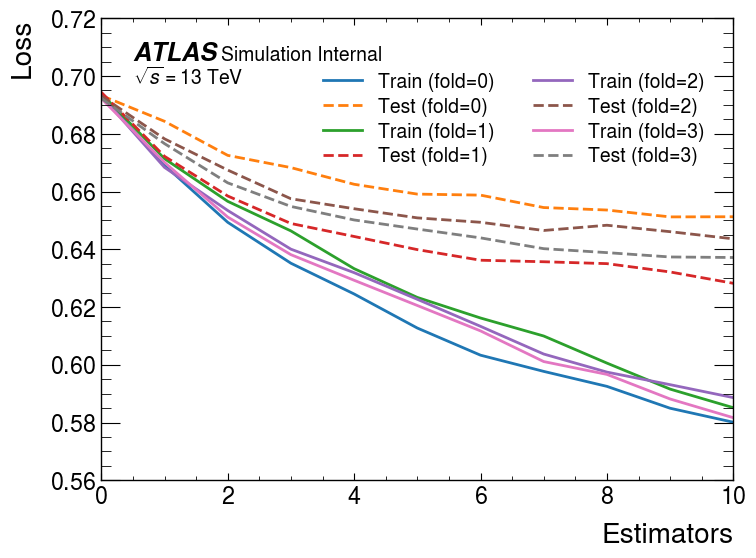

In [100]:
    
    
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend(title=' ',ncols=2)
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
#plt.savefig(f'loss_curve.pdf')

plt.show()

# Multi-class classification

In [7]:
cols = feature_cols+['eventNumber','weight']
aliases = {'weight':'event_norm * weight_mc * weight_pileup * weight_leptonSF * weight_photonSF * weight_jvt * weight_bTagSF_DL1r_Continuous * event_lumi'}

In [8]:
df_sig = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg_prompts = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg_fakes = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10)&(event_nbjets70>=1)',library="pd",aliases=aliases)


In [68]:

nfolds = 4
   
n_estimators = 100

# SINGLE MODEL  : Using XGB Classifier
models = []
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    X_bkg_train_prompts = df_bkg_prompts[feature_cols][df_bkg_prompts['eventNumber']%nfolds != fold]
    w_bkg_train_prompts = df_bkg_prompts['weight'][df_bkg_prompts['eventNumber']%nfolds != fold]

    X_bkg_test_prompts = df_bkg_prompts[feature_cols][df_bkg_prompts['eventNumber']%nfolds == fold]
    w_bkg_test_prompts = df_bkg_prompts['weight'][df_bkg_prompts['eventNumber']%nfolds == fold]
        
    X_bkg_train_fakes = df_bkg_fakes[feature_cols][df_bkg_fakes['eventNumber']%nfolds != fold]
    w_bkg_train_fakes = df_bkg_fakes['weight'][df_bkg_fakes['eventNumber']%nfolds != fold]

    X_bkg_test_fakes = df_bkg_fakes[feature_cols][df_bkg_fakes['eventNumber']%nfolds == fold]
    w_bkg_test_fakes = df_bkg_fakes['weight'][df_bkg_fakes['eventNumber']%nfolds == fold]

    
        
    y_train =  np.concatenate([np.zeros_like(w_sig_train),np.ones_like(w_bkg_train_prompts),2 * np.ones_like(w_bkg_train_fakes)]) #putting classes 0, 1, 2
    X_train =  np.concatenate([X_sig_train,X_bkg_train_prompts,X_bkg_train_fakes])
    w_train =  np.concatenate([w_sig_train,w_bkg_train_prompts,w_bkg_train_fakes])
    y_test  =  np.concatenate([np.zeros_like(w_sig_test),np.ones_like(w_bkg_test_prompts),2 * np.ones_like(w_bkg_test_fakes)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test_prompts,X_bkg_test_fakes])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test_prompts,w_bkg_test_fakes])
    
    print("Signal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test(events,weights): ",len(X_bkg_train_prompts), len(w_bkg_train_prompts), len(X_bkg_train_fakes), len(w_bkg_train_fakes), len(X_bkg_test_prompts), len(w_bkg_test_prompts), len(X_bkg_test_fakes), len(w_bkg_test_fakes))
    

    
    # Initialize XGBoost model for multi-class classification
    #model = XGBClassifier(objective='multi:softmax', num_class=3, use_label_encoder=False)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)

    # Fit model
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    
    """
    for i in range(n_boosters):
            ypred_train = models[-1].predict_proba(X_train, iteration_range=(1, i+1))
            train_loss = metrics.log_loss(y_train, ypred_train, sample_weight=w_train)
            trainloss[fold].append(train_loss)

            ypred_test = models[-1].predict_proba(X_test, iteration_range=(1, i+1))
            test_loss = metrics.log_loss(y_test, ypred_test, sample_weight=w_test)
            testloss[fold].append(test_loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_WP70_Model{execution_count}_PCBTBinVariable_Fold{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    """
    

Signal train test(events,weights):  243054 243054 80846 80846
Background train test(events,weights):  925 925 2104 2104 308 308 685 685
Train scores 0: [0.7374017597577711]
Test scores 0:  [0.5890837359196813]
300
Signal train test(events,weights):  242986 242986 80914 80914
Background train test(events,weights):  925 925 2131 2131 308 308 658 658
Train scores 1: [0.7374017597577711, 0.7342538662667455]
Test scores 1:  [0.5890837359196813, 0.6226625869571225]
300
Signal train test(events,weights):  242824 242824 81076 81076
Background train test(events,weights):  927 927 2079 2079 306 306 710 710
Train scores 2: [0.7374017597577711, 0.7342538662667455, 0.7418630285692513]
Test scores 2:  [0.5890837359196813, 0.6226625869571225, 0.6205569769582324]
300
Signal train test(events,weights):  242836 242836 81064 81064
Background train test(events,weights):  922 922 2053 2053 311 311 736 736
Train scores 3: [0.7374017597577711, 0.7342538662667455, 0.7418630285692513, 0.7377081244983521]
Test 

In [69]:
models[0]

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, objective='multi:softprob', ...)

In [70]:
len(models[0].get_booster().get_dump()) # This ensures we are within the actual range


300

In [48]:
nfolds = 4
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}



In [49]:
n_boosters = len(models[0].get_booster().get_dump())
print(len(X_train))
for i in range(n_boosters):
        ypred_train = models[0].predict_proba(X_train, iteration_range=(0, 2))
        ypred_test = models[0].predict_proba(X_test, iteration_range=(0, 2))
        # Compute the log loss with the true labels and predicted probabilities
        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=w_train)
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=w_test)
        
        # Append the loss values to respective lists
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)

245811


In [ ]:
    
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [72]:
# Works

nfolds = 4
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}

print(n_boosters)

for fold in range(nfolds):
    n_boosters = len(models[fold].get_booster().get_dump()) # This ensures we are within the actual range
    print(n_boosters)
    for i in range(100):   # change these numbers accordingly
        # print("Value of tree:",i)
        # Predict probabilities for a subset of trees from 1 to i+1
        ypred_train = models[fold].predict_proba(X_train, iteration_range=(0, i))
        ypred_test = models[fold].predict_proba(X_test, iteration_range=(0, i))
        
        # Compute the log loss with the true labels and predicted probabilities
        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=w_train)
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=w_test)
        
        # Append the loss values to respective lists
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)

300
300
300
300
300


In [45]:
nfolds = 4
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}

for fold in range(nfolds):
    n_boosters = len(models[fold].get_booster().get_dump()) # This ensures we are within the actual range
    print(n_boosters)
    for i in range(n_boosters):
        
        # Predict probabilities for a subset of trees from 1 to i+1
        ypred_train = models[fold].predict_proba(X_train, iteration_range=(0, i))
        ypred_test = models[fold].predict_proba(X_test, iteration_range=(0, i))
        
        # Compute the log loss with the true labels and predicted probabilities
        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=w_train)
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=w_test)
        
        # Append the loss values to respective lists
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)

90


XGBoostError: [09:38:16] /build/jenkins/workspace/lcg_release_pipeline/build/pyexternals/xgboost-2.0.2/src/xgboost/2.0.2/src/gbm/gbtree.h:125: Check failed: end <= model.BoostedRounds() (31 vs. 30) : Out of range for tree layers.
Stack trace:
  [bt] (0) /cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/lib/libxgboost.so(dmlc::LogMessageFatal::~LogMessageFatal()+0x71) [0x7fd3e09231c1]
  [bt] (1) /cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/lib/libxgboost.so(xgboost::gbm::detail::LayerToTree(xgboost::gbm::GBTreeModel const&, int, int)+0xf9) [0x7fd3e0bf8f19]
  [bt] (2) /cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/lib/libxgboost.so(xgboost::gbm::GBTree::InplacePredict(std::shared_ptr<xgboost::DMatrix>, float, xgboost::PredictionCacheEntry*, int, int) const+0x36) [0x7fd3e0be4c76]
  [bt] (3) /cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/

In [73]:
print((n_estimators))

100


In [74]:
print(len(trainloss)), print(type(trainloss)), print(trainloss[1])

4
<class 'dict'>
[0.7094094585348356, 1.0301360788954794, 0.9842795739621513, 0.9504495306660466, 0.9253743019997259, 0.906900299825399, 0.8907122382245108, 0.8793155650090178, 0.8696103491109002, 0.8602160577275968, 0.8526056190890485, 0.8459353010939874, 0.8402516310976788, 0.8342063144662522, 0.8295212276592547, 0.8252730427206129, 0.8203610367322324, 0.8169489701872327, 0.813145603265286, 0.8100037517964347, 0.8074460433281702, 0.8049944385675839, 0.8025208988465788, 0.7993751797634285, 0.797362316544573, 0.7947945052758778, 0.7936146972569613, 0.792388063057787, 0.7903604508296221, 0.7879623607950177, 0.7859315828223206, 0.7831806883513216, 0.7810358627136148, 0.7793199685301252, 0.7773497133869337, 0.7760632179224113, 0.7741794768291496, 0.7723703743745488, 0.7712358947403344, 0.7700961741242152, 0.768479908288287, 0.7670052751929476, 0.7656013608527923, 0.7636167700322863, 0.7629442112246272, 0.761687937689686, 0.760715976578553, 0.7592683366321752, 0.7580585813679787, 0.7566232

(None, None, None)

In [75]:
print(len(trainloss[1]))
print(trainloss[1])
print(trainloss[1][1])
print(trainloss[1][0:10])

100
[0.7094094585348356, 1.0301360788954794, 0.9842795739621513, 0.9504495306660466, 0.9253743019997259, 0.906900299825399, 0.8907122382245108, 0.8793155650090178, 0.8696103491109002, 0.8602160577275968, 0.8526056190890485, 0.8459353010939874, 0.8402516310976788, 0.8342063144662522, 0.8295212276592547, 0.8252730427206129, 0.8203610367322324, 0.8169489701872327, 0.813145603265286, 0.8100037517964347, 0.8074460433281702, 0.8049944385675839, 0.8025208988465788, 0.7993751797634285, 0.797362316544573, 0.7947945052758778, 0.7936146972569613, 0.792388063057787, 0.7903604508296221, 0.7879623607950177, 0.7859315828223206, 0.7831806883513216, 0.7810358627136148, 0.7793199685301252, 0.7773497133869337, 0.7760632179224113, 0.7741794768291496, 0.7723703743745488, 0.7712358947403344, 0.7700961741242152, 0.768479908288287, 0.7670052751929476, 0.7656013608527923, 0.7636167700322863, 0.7629442112246272, 0.761687937689686, 0.760715976578553, 0.7592683366321752, 0.7580585813679787, 0.7566232331398843, 0.

In [76]:
mplhep.style.use('ATLAS')
nbins = 10

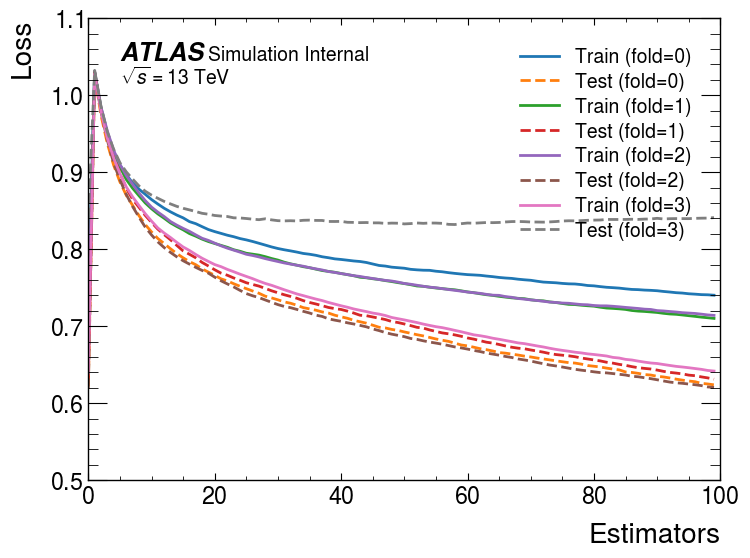

In [77]:
nfolds = 4
n_estimators = 100
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [93]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg_prompts = df_bkg_prompts[feature_cols].to_numpy().astype(np.float32) 
X_bkg_fakes = df_bkg_fakes[feature_cols].to_numpy().astype(np.float32) 


results_sig_list = [model.predict_proba(X_sig)[:,0] for model in models]   #array of bdt scores
results_bkg_prompts_list = [model.predict_proba(X_bkg_prompts)[:,0] for model in models]   #array of bdt scores
results_bkg_fakes_list = [model.predict_proba(X_bkg_fakes)[:,0] for model in models]   #array of bdt scores

"""
print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))
"""

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg_prompts = [df_bkg_prompts['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_prompts = np.select(condlist_bkg_prompts, results_bkg_prompts_list)

condlist_bkg_fakes = [df_bkg_fakes['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_fakes = np.select(condlist_bkg_fakes, results_bkg_fakes_list)

print('Fold separated arrays for BDT scroes:')
print(results_bkg_prompts[1],results_bkg_fakes[1],results_sig[1])
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg_prompts))
print("Length bkg: ", len(results_bkg_fakes))

Fold separated arrays for BDT scroes:
0.21089387 0.7440442 0.7137931
Length sig:  323900
Length bkg:  1233
Length bkg:  2789


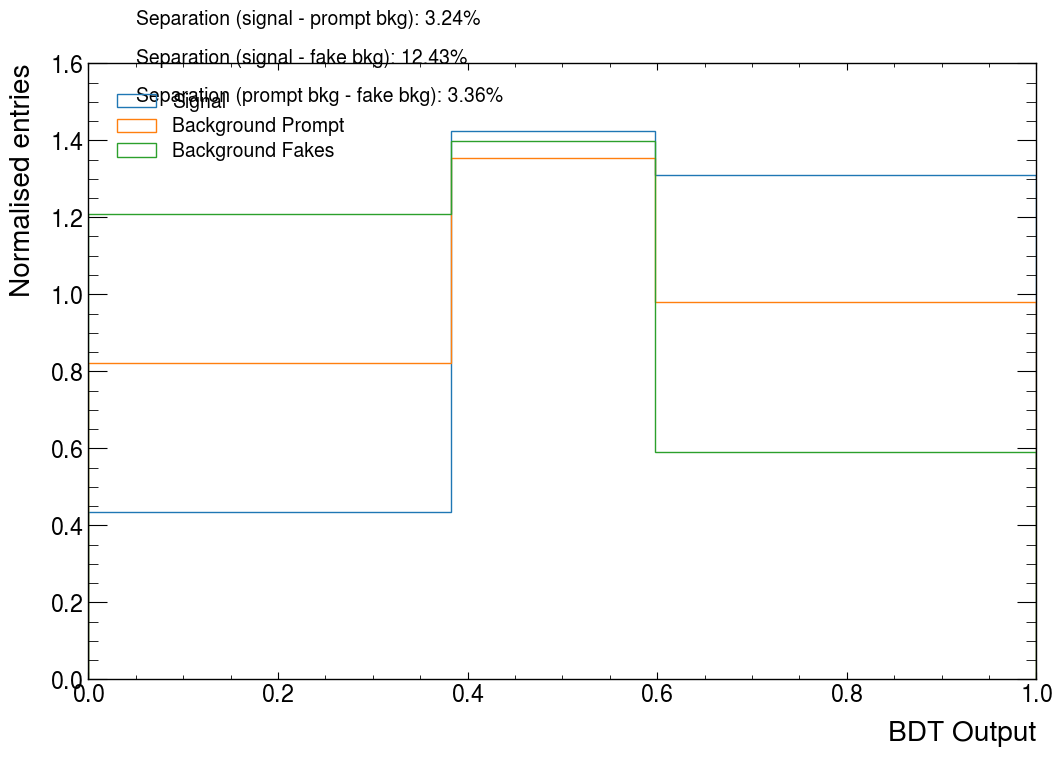

In [94]:
plt.figure(figsize=(12, 8))

# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg_prompt, _, _ = plt.hist(results_bkg_prompts, weights=df_bkg_prompts['weight'], bins=custom_bins, histtype='step', density=True, label='Background Prompt')
bc_bkg_fake, _, _ = plt.hist(results_bkg_fakes, weights=df_bkg_fakes['weight'], bins=custom_bins, histtype='step', density=True, label='Background Fakes')


# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation_sig_bkgPrompt = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_prompt) ** 2) / (bc_sig + bc_bkg_prompt)) * bin_widths)
separation_sig_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_fake) ** 2) / (bc_sig + bc_bkg_fake)) * bin_widths)
separation_bkgPrompt_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_bkg_prompt - bc_bkg_fake) ** 2) / (bc_bkg_prompt + bc_bkg_fake)) * bin_widths)

#separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.7, s=f'Separation (signal - prompt bkg): {separation_sig_bkgPrompt*100:.2f}%')
plt.text(x=0.05, y=1.6, s=f'Separation (signal - fake bkg): {separation_sig_bkgFake*100:.2f}%')
plt.text(x=0.05, y=1.5, s=f'Separation (prompt bkg - fake bkg): {separation_bkgPrompt_bkgFake*100:.2f}%')

#plt.savefig(f'separation_fittedbins.pdf')
plt.legend()


In [83]:
results_bkg = np.concatenate([results_bkg_prompts,results_bkg_fakes])
df_bkg      = np.concatenate([df_bkg_prompts,df_bkg_fakes])


df_bkg_weight = np.concatenate([df_bkg_prompts['weight'],df_bkg_fakes['weight']])

In [84]:
print(df_bkg_prompts['weight'].shape, df_bkg_fakes['weight'].shape)
print(type(df_bkg_prompts['weight']), type(df_bkg_fakes['weight']))
print(df_bkg_weight.shape)  # Should be the sum of the individual shapes
print(df_bkg_weight.dtype)  # Should be consistent, usually float
print(df_bkg_weight)

(1233,) (2789,)
<class 'pandas.core.series.Series'> <class 'pandas.core.series.Series'>
(4022,)
float32
[7.8355055e-03 7.7039963e-03 1.0373352e-02 ... 3.9550854e-04 2.2275517e-02
 1.7932385e-05]


In [85]:
print(results_bkg)
print(len(df_sig))
print(df_sig['weight'][1])
print(len(df_bkg))
print(df_bkg_prompts['weight'][1])
print(df_bkg_weight[1])


[0.5021665  0.21089387 0.30470562 ... 0.21947049 0.45550805 0.33476138]
323900
0.00011641563
4022
0.0078355055
0.0077039963


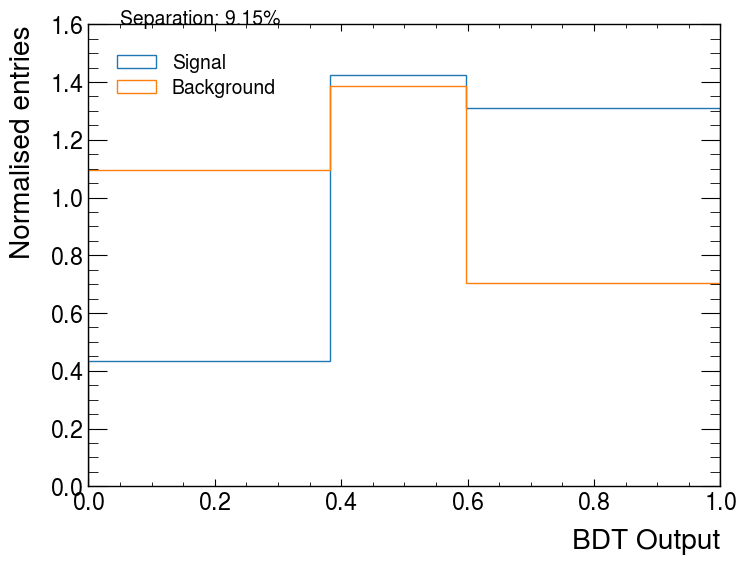

In [86]:
# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg_weight, bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.pdf')
plt.legend()


# Model 6 CURRENT Model -> absolute weight treatment

In [87]:
df_sig_curr = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/injected_model6/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg_curr = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/injected_model6/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/injected_model6/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [89]:
n_estimators = 100

In [90]:
# SINGLE MODEL  : Using XGB Classifier
models_curr = []
nfolds = 4
scores_train,scores_test = [],[]
testloss_curr = {fold:[] for fold in range(nfolds)}
trainloss_curr = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig_curr[feature_cols][df_sig_curr['eventNumber']%nfolds != fold]
    w_sig_train = df_sig_curr['weight'][df_sig_curr['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig_curr[feature_cols][df_sig_curr['eventNumber']%nfolds == fold]
    w_sig_test = df_sig_curr['weight'][df_sig_curr['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg_curr[feature_cols][df_bkg_curr['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg_curr['weight'][df_bkg_curr['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg_curr[feature_cols][df_bkg_curr['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg_curr['weight'][df_bkg_curr['eventNumber']%nfolds == fold]
    
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models_curr.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models_curr[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models_curr[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss_curr[fold].append(loss)
        
        ypred = models_curr[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss_curr[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_WP70_Model{execution_count}_PCBTBinVariable_Fold{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

Train scores 0: [0.7087981045544384]
Test scores 0:  [0.6040963733593898]
100
Train scores 1: [0.7087981045544384, 0.7060952885656401]
Test scores 1:  [0.6040963733593898, 0.6508042671261003]
100
Train scores 2: [0.7087981045544384, 0.7060952885656401, 0.7154218064399481]
Test scores 2:  [0.6040963733593898, 0.6508042671261003, 0.6147454002955082]
100
Train scores 3: [0.7087981045544384, 0.7060952885656401, 0.7154218064399481, 0.7104624446638785]
Test scores 3:  [0.6040963733593898, 0.6508042671261003, 0.6147454002955082, 0.6280105900470212]
100


In [91]:
X_sig = df_sig_curr[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg_curr[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models_curr]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models_curr]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig_curr['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg_curr['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.52952486, 0.5236848 , 0.75406325, ..., 0.7516109 , 0.7994762 ,
       0.5148107 ], dtype=float32), array([0.45852914, 0.620689  , 0.7417382 , ..., 0.76123613, 0.7665413 ,
       0.5137163 ], dtype=float32), array([0.56637573, 0.58218825, 0.81708676, ..., 0.7993171 , 0.6661153 ,
       0.6272167 ], dtype=float32), array([0.49399394, 0.5913098 , 0.76445323, ..., 0.75270635, 0.8006393 ,
       0.540486  ], dtype=float32)]
Bkg:  [array([0.37098515, 0.47036073, 0.7535182 , ..., 0.5829492 , 0.2989148 ,
       0.74003804], dtype=float32), array([0.38735065, 0.5127959 , 0.683452  , ..., 0.14488952, 0.33860564,
       0.7021031 ], dtype=float32), array([0.524535  , 0.6023463 , 0.6442872 , ..., 0.11581323, 0.29620817,
       0.63255006], dtype=float32), array([0.42024714, 0.6365962 , 0.68811786, ..., 0.1317758 , 0.63591003,
       0.63013434], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3959


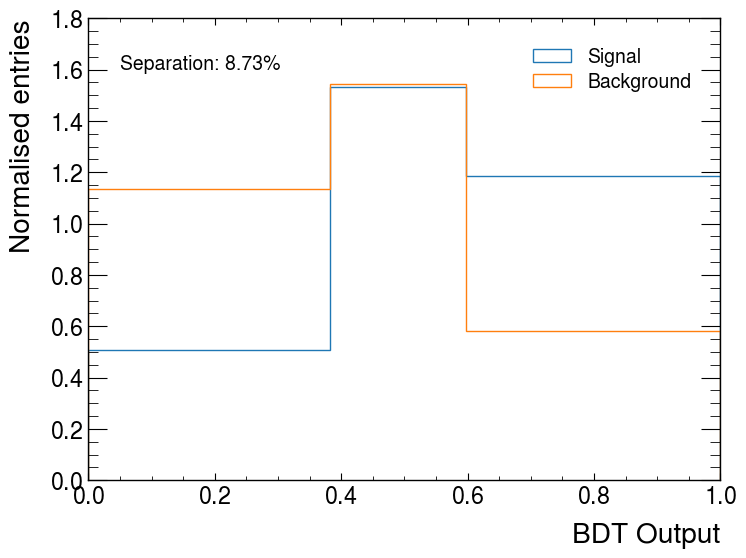

In [92]:

# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig_curr['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg_curr['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')

#plt.savefig(f'separation_fittedbins.pdf')
plt.legend()


# Separation checks and differences

In [123]:
df_sig_curr

,"jet_pt[:,0]","jet_pt[:,1]",met_met,"ph_eta[:,0]","ph_eta[:,1]","ph_pt[:,0]","ph_pt[:,1]","ph_mlph_closest[:,0]","ph_mlph_closest[:,1]",diph_M,...,dr_lep_ph1,"ph_conversion_type[:,1]","ph_conversion_type[:,0]","ph_mphb70_closest[:,0]","ph_mphb70_closest[:,1]",m_AllObjects,jet_tagWeightBin_DL1r_Continuous_Max,dr_ph,eventNumber,weight
entry,,,,,,,,,,,,,,,,,,,,,
0,150484.406250,73511.679688,94067.289062,-0.810186,-2.244604,69320.984375,40159.082031,111921.437500,85738.242188,133776.865720,...,2.024914,0,0,194193.109375,180407.515625,6.623719e+05,5,3.378159,3027797,0.000135
1,86847.671875,80147.335938,82253.992188,-1.637574,-0.324506,53704.890625,35219.238281,27673.837891,64343.531250,74462.356831,...,1.434242,0,3,57904.761719,72231.742188,4.406062e+05,5,1.659672,3027102,0.000116
2,181402.812500,68254.507812,74853.023438,-1.589558,0.736558,42865.250000,27759.439453,133010.531250,27641.623047,111520.412037,...,0.653988,0,0,60826.246094,67986.234375,7.907606e+05,5,2.839720,3028897,0.000126
3,116658.945312,94503.289062,69712.125000,0.430313,0.505207,42064.648438,26476.435547,25071.738281,28849.996094,21508.374635,...,0.877128,2,0,77931.437500,48659.343750,4.121142e+05,5,0.655882,3028080,0.000097
4,82132.882812,78624.007812,33878.414062,-0.062155,-0.815561,108229.054688,41661.660156,145042.515625,152483.781250,116703.205514,...,3.736127,3,0,183255.281250,147042.578125,5.767382e+05,5,1.937684,3028336,0.000118
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
344938,71285.031250,57015.062500,75461.968750,0.904379,1.141591,190343.843750,61934.832031,326736.437500,82275.203125,213865.170670,...,0.886916,0,0,66798.328125,88094.531250,7.363506e+05,5,2.728336,25751603,0.000112
344939,166067.734375,104941.835938,24278.585938,-0.876851,-0.836196,46650.816406,35900.187500,93446.640625,64376.882812,40608.637254,...,1.776421,2,0,63590.570312,100244.632812,1.421678e+06,5,1.038147,25750718,0.000095
344940,205166.015625,79174.453125,92005.109375,-1.571626,0.034160,93579.375000,20139.976562,156148.546875,29751.898438,102275.933173,...,1.157627,0,0,85318.710938,53956.492188,6.608800e+05,5,2.379286,25750331,0.000119


In [124]:
df_sig

,"jet_pt[:,0]","jet_pt[:,1]",met_met,"ph_eta[:,0]","ph_eta[:,1]","ph_pt[:,0]","ph_pt[:,1]","ph_mlph_closest[:,0]","ph_mlph_closest[:,1]",diph_M,...,dr_lep_ph1,"ph_conversion_type[:,1]","ph_conversion_type[:,0]","ph_mphb70_closest[:,0]","ph_mphb70_closest[:,1]",m_AllObjects,jet_tagWeightBin_DL1r_Continuous_Max,dr_ph,eventNumber,weight
entry,,,,,,,,,,,,,,,,,,,,,
0,150484.406250,73511.679688,94067.289062,-0.810186,-2.244604,69320.984375,40159.082031,111921.437500,85738.242188,133776.865720,...,2.024914,0,0,194193.109375,180407.515625,6.623719e+05,5,3.378159,3027797,0.000135
1,86847.671875,80147.335938,82253.992188,-1.637574,-0.324506,53704.890625,35219.238281,27673.837891,64343.531250,74462.356831,...,1.434242,0,3,57904.761719,72231.742188,4.406062e+05,5,1.659672,3027102,0.000116
2,181402.812500,68254.507812,74853.023438,-1.589558,0.736558,42865.250000,27759.439453,133010.531250,27641.623047,111520.412037,...,0.653988,0,0,60826.246094,67986.234375,7.907606e+05,5,2.839720,3028897,0.000126
3,116658.945312,94503.289062,69712.125000,0.430313,0.505207,42064.648438,26476.435547,25071.738281,28849.996094,21508.374635,...,0.877128,2,0,77931.437500,48659.343750,4.121142e+05,5,0.655882,3028080,0.000097
4,82132.882812,78624.007812,33878.414062,-0.062155,-0.815561,108229.054688,41661.660156,145042.515625,152483.781250,116703.205514,...,3.736127,3,0,183255.281250,147042.578125,5.767382e+05,5,1.937684,3028336,0.000118
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
344938,71285.031250,57015.062500,75461.968750,0.904379,1.141591,190343.843750,61934.832031,326736.437500,82275.203125,213865.170670,...,0.886916,0,0,66798.328125,88094.531250,7.363506e+05,5,2.728336,25751603,0.000112
344939,166067.734375,104941.835938,24278.585938,-0.876851,-0.836196,46650.816406,35900.187500,93446.640625,64376.882812,40608.637254,...,1.776421,2,0,63590.570312,100244.632812,1.421678e+06,5,1.038147,25750718,0.000095
344940,205166.015625,79174.453125,92005.109375,-1.571626,0.034160,93579.375000,20139.976562,156148.546875,29751.898438,102275.933173,...,1.157627,0,0,85318.710938,53956.492188,6.608800e+05,5,2.379286,25750331,0.000119


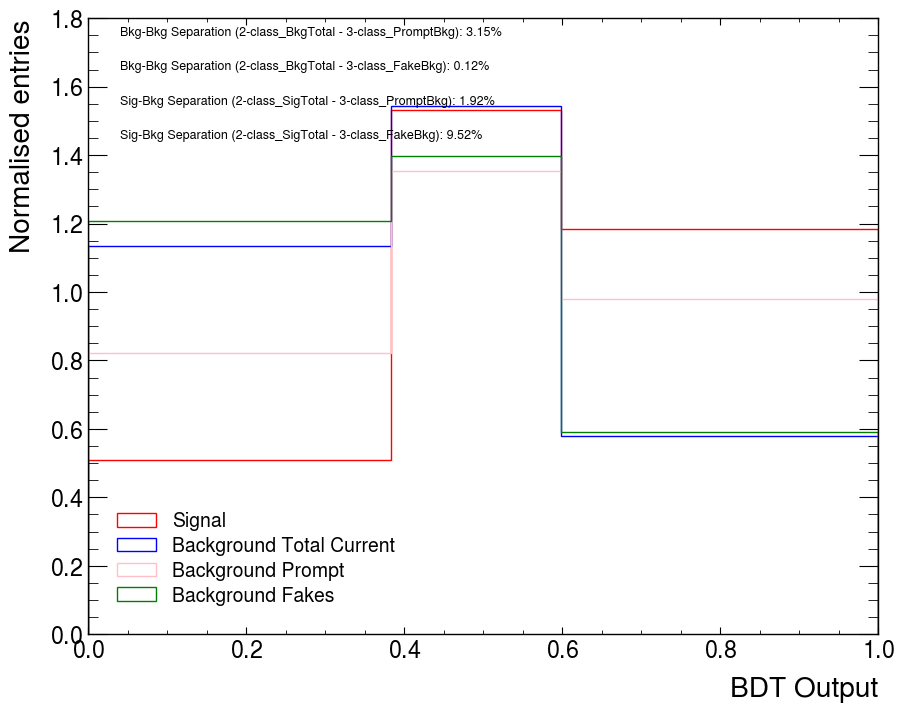

In [135]:
fig,ax = plt.subplots(figsize=(10, 8))  # Adjust width and height for desired size


# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig_curr['weight'], bins=custom_bins, histtype='step', density=True, label='Signal',color='red')
bc_bkg_curr, _, _ = plt.hist(results_bkg, weights=df_bkg_curr['weight'], bins=custom_bins, histtype='step', density=True, label='Background Total Current',color='blue')


#bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg_weight, bins=custom_bins, histtype='step', density=True, label='Background Prompt')

bc_bkg_prompt, _, _ = plt.hist(results_bkg_prompts, weights=df_bkg_prompts['weight'], bins=custom_bins, histtype='step', density=True, label='Background Prompt',color='pink')
bc_bkg_fake, _, _ = plt.hist(results_bkg_fakes, weights=df_bkg_fakes['weight'], bins=custom_bins, histtype='step', density=True, label='Background Fakes',color='green')


# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation_curr_prompt = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

separation_bkgTotalCurr_bkgPrompt = 0.5 * np.sum(np.nan_to_num(((bc_bkg_curr - bc_bkg_prompt) ** 2) / (bc_bkg_curr + bc_bkg_prompt)) * bin_widths)
separation_bkgTotalCurr_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_bkg_curr - bc_bkg_fake) ** 2) / (bc_bkg_curr + bc_bkg_fake)) * bin_widths)

separation_sig_bkgPrompt = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_prompt) ** 2) / (bc_sig + bc_bkg_prompt)) * bin_widths)
separation_sig_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_fake) ** 2) / (bc_sig + bc_bkg_fake)) * bin_widths)


# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.04, y=1.75, s=f'Bkg-Bkg Separation (2-class_BkgTotal - 3-class_PromptBkg): {separation_bkgTotalCurr_bkgPrompt*100:.2f}%',fontsize=9)
plt.text(x=0.04, y=1.65, s=f'Bkg-Bkg Separation (2-class_BkgTotal - 3-class_FakeBkg): {separation_bkgTotalCurr_bkgFake*100:.2f}%',fontsize=9)
plt.text(x=0.04, y=1.55, s=f'Sig-Bkg Separation (2-class_SigTotal - 3-class_PromptBkg): {separation_sig_bkgPrompt*100:.2f}%',fontsize=9)
plt.text(x=0.04, y=1.45, s=f'Sig-Bkg Separation (2-class_SigTotal - 3-class_FakeBkg): {separation_sig_bkgFake*100:.2f}%',fontsize=9)


#plt.savefig(f'separation_fittedbins.pdf')
plt.legend()



